# YOLO26: vehicle detection and traffic counting

This lesson goes one step beyond object detection: **from "how many vehicles are in this image" to
"how many vehicles passed during a time window"**. The dataset is the official
[vehicle-counting-rtvul / vehicle-counting-tksu5 v4](https://universe.roboflow.com/vehicle-counting-rtvul/vehicle-counting-tksu5/dataset/4)
YOLO26 export (CC BY 4.0): 6,565 images in five classes, `0=truck, 1=bicycle, 2=bus, 3=car, 4=motorcycle`.
The importer lowercases class names at their original IDs, and three source lines that were segmentation
polygons were rewritten as their bounding boxes (recorded in `provenance.json`).

Three ideas that must not be mixed up:

| Task | Question | What it needs |
|---|---|---|
| Detection counting | How many vehicles are in this image | Per-frame boxes + a de-duplication rule |
| Traffic counting | How many vehicles passed | Tracking IDs + line-crossing logic |
| Flow rate | How many vehicles per minute | Crossings divided by video duration |

> **Every code cell is followed by an "Expected output" cell**: text is quoted verbatim and figures are
> exported to `assets/` and linked with relative paths, so the recorded results stay readable after
> **Kernel -> Clear All Outputs**. Re-running should reproduce them. The recorded run is the Apple silicon
> MPS execution of 2026-10-18 on the `env_dl_uv` kernel (5 epochs, 320 px, `seed=42`, 940.21 s end to end,
> and the Chinese edition under the same parameters and seed matches it cell for cell); the full write-up
> is the [run report](../lessons/05-vehicle-counting-run-report.md).

Place the dataset in the course data directory first. Classroom data is staged outside the repository in
DataSet (classroom mirror `/workspace/DataSet/yolo`); from the repository root:

```powershell
.\english\02-object-detection\.venv\Scripts\python.exe .\english\scripts\import_vehicle_counting.py --from-staging
.\start-notebooks.ps1 -Module detection
```

On macOS/Linux the single uv environment `~/env_dl_uv` (Jupyter kernel `env_dl_uv`) replaces the launcher;
see [environment setup](../../docs/environment-setup.md). `COURSE_SMOKE=1` switches to COCO8 as a pure
pipeline check and is not the vehicle experiment; `COURSE_EPOCHS` only shortens training. The video defaults
to a short clip that `build_traffic_demo_video.py` composes from real vehicle crops in the dataset (every
vehicle appears once and crosses once, so there is a definite answer); set `TRAFFIC_VIDEO=<your.mp4>` to
analyse your own road video.

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('torch').split("+")[0] == '2.14.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('torch' + ":", version('torch'))
print("Run mode:", 'Default classroom training parameters')

Python: 3.12.12
torch: 2.14.1
Run mode: Default classroom training parameters


**Expected output:**

```text
Python: 3.12.12
torch: 2.14.1
Run mode: Default classroom training parameters
```

In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None:
    COURSE = next((p / "english" for p in [start, *start.parents]
                   if (p / "english" / "COURSE_ROOT").is_file()), None)
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
sys.path.insert(0, str(COURSE / "scripts"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'/Users/will/workspace/deep-learning-lab/english/data/torch-cache'

**Expected output:**

```text
'…/deep-learning-lab/english/data/torch-cache'
```

(Inside the quoted output `…` stands for the repository's absolute path prefix on the machine that ran the notebook; yours will show your own path.)

In [3]:
import json
import warnings

from collections import Counter

import numpy

MODULE = COURSE / "02-object-detection"
OUTPUT = MODULE / "outputs"
# Keep Ultralytics settings local to this edition, before importing the package.
os.environ["YOLO_CONFIG_DIR"] = str(OUTPUT / "ultralytics-config")
import cv2
import torch
from ultralytics import YOLO, settings
import ultralytics
from ultralytics.utils import set_logging
import matplotlib.pyplot as plt
import yaml
from detection_data import (prepare_vehicle_counting, VEHICLE_CLASSES, VEHICLE_DIRECTORY,
                            VEHICLE_SOURCE)
from traffic_counting import (VEHICLE_CLASSES as TALLY_CLASSES, LineCrossingCounter,
                              count_video, ground_truth_counts, tally_predictions)
from build_traffic_demo_video import build as build_demo_video

OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
settings.update({"datasets_dir": str(MODULE / "data"),
                 "weights_dir": str(OUTPUT / "weights"),
                 "runs_dir": str(OUTPUT / "runs")})
# Ultralytics redraws a per-iteration progress bar; inside a saved notebook every redraw
# becomes a stored output record, so raise its log level and read the curve from results.png.
set_logging(verbose=False)
torch.set_num_threads(4)
DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")

# Ultralytics turns on warn-only determinism (seed plus torch.use_deterministic_algorithms).
# On Apple Silicon the autograd kernel index_put_with_accumulate_mps has no deterministic
# implementation, so that warning repeats once per epoch and buries the training log. It is
# silenced here; the caveat stays real: on MPS a rerun matches in aggregate, not bit-for-bit.
warnings.filterwarnings(
    "ignore",
    message="index_put_with_accumulate_mps does not have a deterministic implementation")
PRETRAINED = "yolo11n.pt"      # COCO pretrained: zero-shot baseline with 80 classes.
FINETUNE = "yolo26n.pt"        # Base weights fine-tuned here on the five vehicle classes.
EPOCHS = int(os.environ.get("COURSE_EPOCHS", 1 if SMOKE else 5))
IMGSZ = 64 if SMOKE else 320
BATCH = 2 if SMOKE else 8
COUNTING_LINE = ((0, 320), (640, 320))   # Data images are square 640x640 exports.
print("Ultralytics version:", ultralytics.__version__)
print("Device:", DEVICE, "| epochs:", EPOCHS, "| imgsz:", IMGSZ, "| smoke:", SMOKE)

Ultralytics version: 8.4.177
Device: mps | epochs: 5 | imgsz: 320 | smoke: False


**Expected output:**

```text
Ultralytics version: 8.4.177
Device: mps | epochs: 5 | imgsz: 320 | smoke: False
```

## 1. Verify the dataset and class mapping

Each YOLO row is `class_id x_center y_center width height`, normalised by image width and height. The
importer already checked the Roboflow source metadata, the class set, split independence, and duplicate
images across splits. Here we read the measured counts and keep "images" and "annotation boxes" apart -
traffic experiments care about object counts, not image counts.

In [4]:
if SMOKE:
    from detection_data import prepare_coco8
    DATA_CONFIG = str(prepare_coco8(MODULE / "data", OUTPUT / "coco8-smoke-vehicle.yaml"))
    print("SMOKE TEST ONLY: COCO8 pipeline check; not the vehicle experiment.")
    EXPORT = None
else:
    EXPORT = MODULE / "data" / VEHICLE_DIRECTORY
    DATA_CONFIG = OUTPUT / "vehicle-counting-data.yaml"
    config, counts = prepare_vehicle_counting(EXPORT, DATA_CONFIG)
    provenance = json.loads((EXPORT / "provenance.json").read_text(encoding="utf-8"))
    print("Class mapping:", dict(enumerate(config["names"])))
    print("Validated split sizes:", {k: v for k, v in counts.items()})
    print("Source:", provenance["source"], "| license:", provenance["license"])
    print("Archive SHA-256:", (provenance["archive_sha256"] or "not recorded")[:16], "...")
    DATA_CONFIG = str(DATA_CONFIG)

Class mapping: {0: 'truck', 1: 'bicycle', 2: 'bus', 3: 'car', 4: 'motorcycle'}
Validated split sizes: {'train': {'images': 4708, 'boxes': 52668}, 'val': {'images': 1661, 'boxes': 18810}, 'test': {'images': 196, 'boxes': 2120}, 'segmentation_lines_normalised': 0}
Source: https://universe.roboflow.com/vehicle-counting-rtvul/vehicle-counting-tksu5 | license: CC BY 4.0
Archive SHA-256: 3945432ed7ce76c9 ...


**Expected output:**

```text
Class mapping: {0: 'truck', 1: 'bicycle', 2: 'bus', 3: 'car', 4: 'motorcycle'}
Validated split sizes: {'train': {'images': 4708, 'boxes': 52668}, 'val': {'images': 1661, 'boxes': 18810}, 'test': {'images': 196, 'boxes': 2120}, 'segmentation_lines_normalised': 0}
Source: https://universe.roboflow.com/vehicle-counting-rtvul/vehicle-counting-tksu5 | license: CC BY 4.0
Archive SHA-256: 3945432ed7ce76c9 ...
```

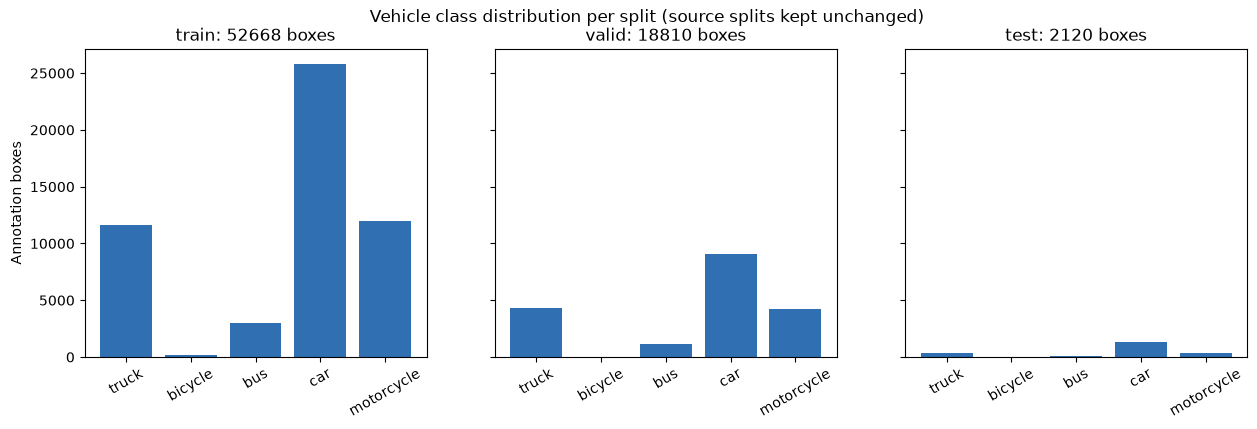

In [5]:
if SMOKE:
    print("COCO8 smoke mode skips the vehicle label census.")
else:
    def split_census(split):
        counter = Counter()
        for label in (EXPORT / split / "labels").glob("*.txt"):
            for line in label.read_text(encoding="utf-8").splitlines():
                fields = line.split()
                if len(fields) == 5:
                    counter[config["names"][int(fields[0])]] += 1
        return counter

    figure, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for axis, split in zip(axes, ("train", "valid", "test")):
        census = split_census(split)
        axis.bar(range(len(VEHICLE_CLASSES)), [census[name] for name in VEHICLE_CLASSES],
                 color="#2f6fb2")
        axis.set_xticks(range(len(VEHICLE_CLASSES)), VEHICLE_CLASSES, rotation=30)
        axis.set_title(f"{split}: {sum(census.values())} boxes")
    axes[0].set_ylabel("Annotation boxes")
    figure.suptitle("Vehicle class distribution per split (source splits kept unchanged)")
    plt.show()

**Expected output (image):**

![Class distribution of annotation boxes per split (source splits, no resampling)](../assets/vehicle-counting-1.png)

*Class distribution of annotation boxes per split (source splits, no resampling)*

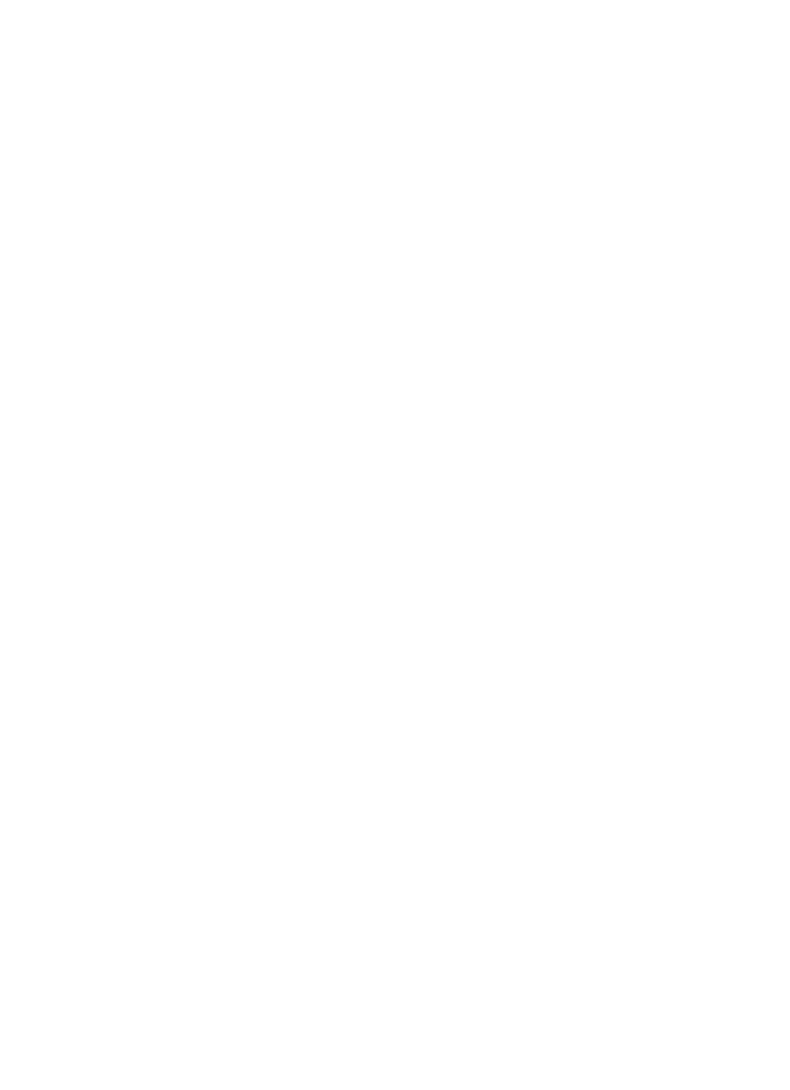

In [6]:
if SMOKE:
    print("COCO8 smoke mode skips the per-class sample grid.")
else:
    def show_class_samples(per_class=2, columns=3):
        rows = max(1, columns - 1)
        figure, axes = plt.subplots(len(VEHICLE_CLASSES), rows,
                                    figsize=(4 * rows, 2.2 * len(VEHICLE_CLASSES)))
        axes = numpy.atleast_2d(axes)
        for row, name in enumerate(VEHICLE_CLASSES):
            shown = 0
            for image in sorted((EXPORT / "valid" / "images").glob("*.jpg")):
                if shown == rows:
                    break
                label = image.with_name(image.stem + ".txt")
                if not label.exists():
                    continue
                lines = [l.split() for l in label.read_text(encoding="utf-8").splitlines()
                         if len(l.split()) == 5]
                hits = [f for f in lines if config["names"][int(f[0])] == name]
                if not hits:
                    continue
                picture = cv2.imread(str(image))
                height, width = picture.shape[:2]
                fields = hits[0]
                x, y, w, h = map(float, fields[1:])
                pad = 0.35
                left = max(0, int((x - w / 2 - w * pad) * width))
                right = min(width, int((x + w / 2 + w * pad) * width))
                top = max(0, int((y - h / 2 - h * pad) * height))
                bottom = min(height, int((y + h / 2 + h * pad) * height))
                axis = axes[row, shown] if rows > 1 else axes[row]
                axis.imshow(cv2.cvtColor(picture[top:bottom, left:right], cv2.COLOR_BGR2RGB))
                axis.set_title(f"{name} ({shown + 1})", fontsize=10)
                axis.axis("off")
                shown += 1
            for extra in range(shown, rows):
                axis = axes[row, extra] if rows > 1 else axes[row]
                axis.axis("off")
        plt.tight_layout()
        plt.show()

    show_class_samples()

**Expected output (image):**

![Grid of annotated samples (the number inside each box is its class id)](../assets/vehicle-counting-2.png)

*Grid of annotated samples (the number inside each box is its class id)*

## 2. Zero-shot baseline: what does inference without fine-tuning give?

A COCO pretrained model does not know this dataset's five class IDs, but it already knows vehicle classes
such as `car / bus / truck / motorcycle`. We map the COCO names onto the five course classes and compare
with this dataset's ground truth. The teaching point: **measure the untrained error first**, then decide
whether fine-tuning is worth it and where the counting error comes from.

In [7]:
COCO_TO_COURSE = {"car": "car", "motorcycle": "motorcycle", "bus": "bus",
                  "truck": "truck", "pickup truck": "truck", "tractor": "truck"}

def ground_truth(image):
    # Labels live in the sibling labels/ directory, not next to the image.
    return ground_truth_counts(image, config["names"])

def tally_to_course(boxes, names):
    raw = tally_predictions(boxes, names, vehicle_classes=tuple(COCO_TO_COURSE))
    merged = Counter()
    for coco_name, quantity in raw["per_class"].items():
        merged[COCO_TO_COURSE[coco_name]] += quantity
    return dict(merged), raw["total"]

if SMOKE:
    print("COCO8 smoke mode skips the zero-shot comparison.")
else:
    zero_shot = YOLO(OUTPUT / "weights" / PRETRAINED)
    samples = sorted((EXPORT / "test" / "images").glob("*.jpg"))[:6]
    rows = []
    for image in samples:
        result = zero_shot.predict(str(image), conf=0.25, imgsz=IMGSZ, device=DEVICE,
                                   verbose=False)[0]
        predicted, total = tally_to_course(result.boxes, zero_shot.names)
        truth = ground_truth(image)
        rows.append((image.name[:34], sum(truth.values()), total,
                     sum(abs(truth.get(k, 0) - predicted.get(k, 0))
                         for k in set(truth) | set(predicted))))
    print(f"{'image':36} {'GT':>4} {'pred':>5} {'abs error':>9}")
    for name, gt, pred, error in rows:
        print(f"{name:36} {gt:4d} {pred:5d} {error:9d}")
    print("Zero-shot mean absolute counting error:",
          round(sum(r[3] for r in rows) / len(rows), 2), "vehicles/image")

image                                  GT  pred abs error
000000021136_jpg.rf.591a09eb79057b      5     3         2
000000279222_jpg.rf.fb7dc97a15f0d2      4     4         0
000000305803_jpg.rf.a12ac5644291b0     13     0        13
000000306789_jpg.rf.fbe2b1ca62b53a      1     1         0
000000306893_jpg.rf.4c136a12ec3d5c      2     4         2
000000314251_jpg.rf.6fc0048d77bbd3      9     0         9
Zero-shot mean absolute counting error: 4.33 vehicles/image


**Expected output:**

```text
image                                  GT  pred abs error
000000021136_jpg.rf.591a09eb79057b      5     3         2
000000279222_jpg.rf.fb7dc97a15f0d2      4     4         0
000000305803_jpg.rf.a12ac5644291b0     13     0        13
000000306789_jpg.rf.fbe2b1ca62b53a      1     1         0
000000306893_jpg.rf.4c136a12ec3d5c      2     4         2
000000314251_jpg.rf.6fc0048d77bbd3      9     0         9
Zero-shot mean absolute counting error: 4.33 vehicles/image
```

## 3. Fine-tune YOLO26n

`yolo26n.pt` is downloaded on first use. Classroom defaults are 5 epochs, 320 px, batch 8 - about three
minutes per epoch on Apple silicon MPS, and remember `COURSE_EPOCHS=1` is a pipeline check, not a classroom
result. The per-iteration progress bar is suppressed; the loss and mAP curves are shown directly below.

Saved checkpoint: /Users/will/workspace/deep-learning-lab/english/02-object-detection/outputs/runs/vehicle-counting-v4-yolo26n-2/weights/best.pt


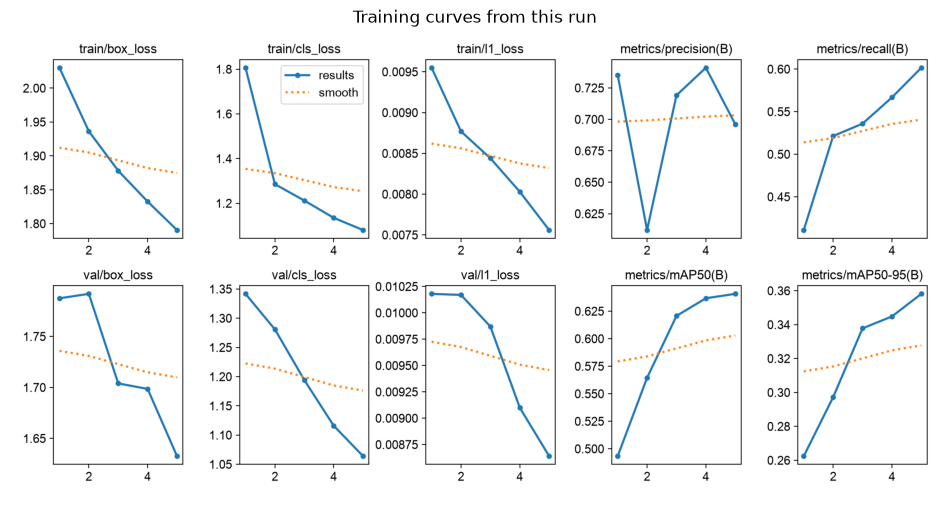

In [8]:
weights = OUTPUT / "weights" / FINETUNE
weights.parent.mkdir(parents=True, exist_ok=True)
model = YOLO(str(weights))
# Defaults are teaching parameters; runtime depends on the current dataset and hardware.
results = model.train(data=DATA_CONFIG, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, workers=0,
                      device=DEVICE, seed=42, deterministic=True, verbose=False,
                      project=str(OUTPUT / "runs"),
                      name="coco8-smoke-vehicle" if SMOKE else "vehicle-counting-v4-yolo26n",
                      exist_ok=False, plots=True)
best = Path(model.trainer.best)
if not best.exists():
    raise RuntimeError("Training did not produce a best checkpoint.")
print("Saved checkpoint:", best)

curves = Path(model.trainer.save_dir) / "results.png"
if curves.exists():
    figure, axis = plt.subplots(figsize=(12, 8))
    axis.imshow(plt.imread(curves))
    axis.axis("off")
    axis.set_title("Training curves from this run")
    plt.show()
else:
    print("Expected plot not found:", curves)

**Expected output:**

```text
Saved checkpoint: …/deep-learning-lab/english/02-object-detection/outputs/runs/vehicle-counting-v4-yolo26n-2/weights/best.pt
```

(Inside the quoted output `…` stands for the repository's absolute path prefix on the machine that ran the notebook; yours will show your own path.)

**Expected output (image):**

![Training curves from this run (five epochs at imgsz 320, Apple silicon MPS)](../assets/vehicle-counting-3.png)

*Training curves from this run (five epochs at imgsz 320, Apple silicon MPS)*

## 4. Evaluate the fine-tuned checkpoint

Validation selects the settings, the test set is for final evaluation only. `precision` and `recall` mean
different things for traffic counting: false positives inflate the count, missed vehicles deflate it. The
per-class table shows which class fails most, usually distant cars and occluded vehicles.

test precision: 0.7308
test recall:    0.6444
test mAP50:     0.6983
test mAP50-95:  0.4071
Metric report written: /Users/will/workspace/deep-learning-lab/english/02-object-detection/outputs/vehicle-counting-metrics.json


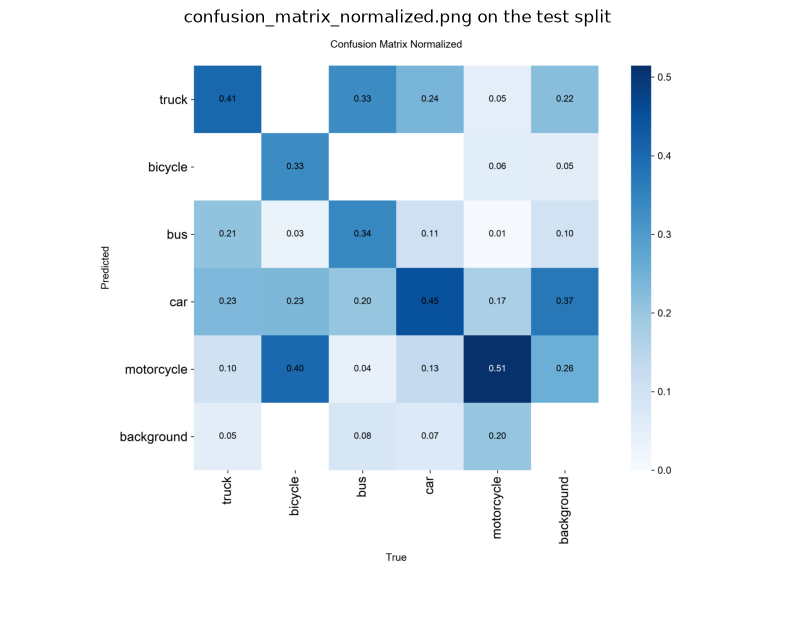

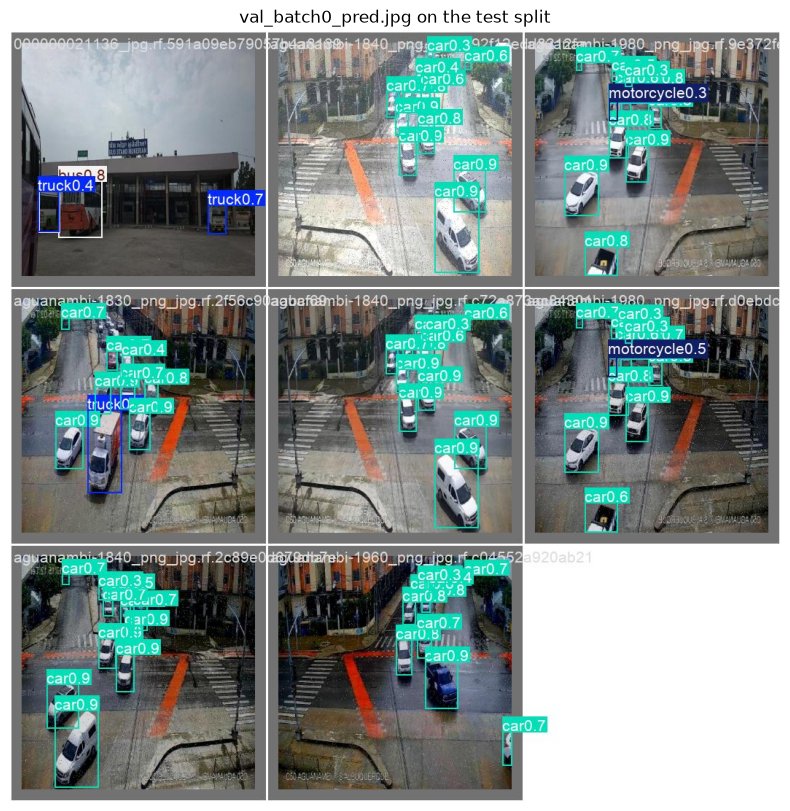

In [9]:
trained = YOLO(str(best))
if SMOKE:
    split, evaluation = "val", trained.val(data=DATA_CONFIG, split="val", device=DEVICE,
                                           imgsz=IMGSZ, workers=0, batch=BATCH,
                                           project=str(OUTPUT / "runs"), name="evaluation-smoke")
else:
    split, evaluation = "test", trained.val(data=DATA_CONFIG, split="test", device=DEVICE,
                                            imgsz=IMGSZ, workers=0, batch=BATCH,
                                            project=str(OUTPUT / "runs"),
                                            name="evaluation-vehicle")
print(f"{split} precision: {evaluation.box.mp:.4f}")
print(f"{split} recall:    {evaluation.box.mr:.4f}")
print(f"{split} mAP50:     {evaluation.box.map50:.4f}")
print(f"{split} mAP50-95:  {evaluation.box.map:.4f}")
per_class = {}
ap_index = {int(c): i for i, c in enumerate(evaluation.box.ap_class_index)}
evaluated_names = dict(enumerate(config["names"])) if not SMOKE else dict(evaluation.names)
for class_id, name in evaluated_names.items():
    if SMOKE or class_id not in ap_index:
        per_class[name] = {"ap50": None, "ap50_95": None}
    else:
        position = ap_index[class_id]
        per_class[name] = {"ap50": float(evaluation.box.ap50[position]),
                           "ap50_95": float(evaluation.box.ap[position])}
report = {"smoke_test": SMOKE, "evaluation_split": split,
          "dataset": "COCO8" if SMOKE else VEHICLE_DIRECTORY,
          "dataset_provenance": {} if SMOKE else provenance,
          "precision": float(evaluation.box.mp), "recall": float(evaluation.box.mr),
          "map50": float(evaluation.box.map50), "map50_95": float(evaluation.box.map),
          "per_class": per_class, "epochs": EPOCHS, "imgsz": IMGSZ,
          "ultralytics_version": ultralytics.__version__}
(OUTPUT / ("smoke-vehicle-metrics.json" if SMOKE else "vehicle-counting-metrics.json")).write_text(
    json.dumps(report, indent=2), encoding="utf-8")
print("Metric report written:", OUTPUT / ("smoke-vehicle-metrics.json" if SMOKE
                                         else "vehicle-counting-metrics.json"))

for name in ("confusion_matrix_normalized.png", "val_batch0_pred.jpg"):
    figure_path = Path(evaluation.save_dir) / name
    if figure_path.exists():
        figure, axis = plt.subplots(figsize=(10, 10))
        axis.imshow(plt.imread(figure_path))
        axis.axis("off")
        axis.set_title(f"{name} on the {split} split")
        plt.show()
    else:
        print("Expected plot not found:", figure_path)

**Expected output:**

```text
test precision: 0.7308
test recall:    0.6444
test mAP50:     0.6983
test mAP50-95:  0.4071
Metric report written: …/deep-learning-lab/english/02-object-detection/outputs/vehicle-counting-metrics.json
```

(Inside the quoted output `…` stands for the repository's absolute path prefix on the machine that ran the notebook; yours will show your own path.)

**Expected output (image):**

![Normalised confusion matrix on the test split](../assets/vehicle-counting-4.png)

*Normalised confusion matrix on the test split*

**Expected output (image):**

![Prediction samples on the test split (blue ground truth, cyan predictions)](../assets/vehicle-counting-5.png)

*Prediction samples on the test split (blue ground truth, cyan predictions)*

## 5. Counting vehicles in images: "how many vehicles are in this frame"

Run whole-image inference with the fine-tuned weights, tally per class, and draw the boxes. Points to note:

- Tracking IDs are not needed within one image, but low-confidence jitter still has to be removed, so state
  the `conf` threshold.
- Only the five configured vehicle classes are counted; if one vehicle becomes two boxes, the count is too
  high, which is one source of counting error.
- Print the predicted count next to the annotated ground-truth count so the error is measurable, instead of
  judging by how nice the picture looks.

000000021136_jpg.rf.591a09eb79057b4a8139188b25aabd95.jpg: predicted {'bus': 4, 'truck': 3} | ground truth {'bus': 4, 'truck': 1}
000000279222_jpg.rf.fb7dc97a15f0d237311be501e45f110a.jpg: predicted {'bus': 3, 'truck': 2, 'car': 1} | ground truth {'bus': 3, 'truck': 1}
000000305803_jpg.rf.a12ac5644291b03859ee97bf32999079.jpg: predicted {'motorcycle': 1} | ground truth {'motorcycle': 13}
000000306789_jpg.rf.fbe2b1ca62b53abcb7fb9fbc765b29e0.jpg: predicted {'motorcycle': 1} | ground truth {'motorcycle': 1}


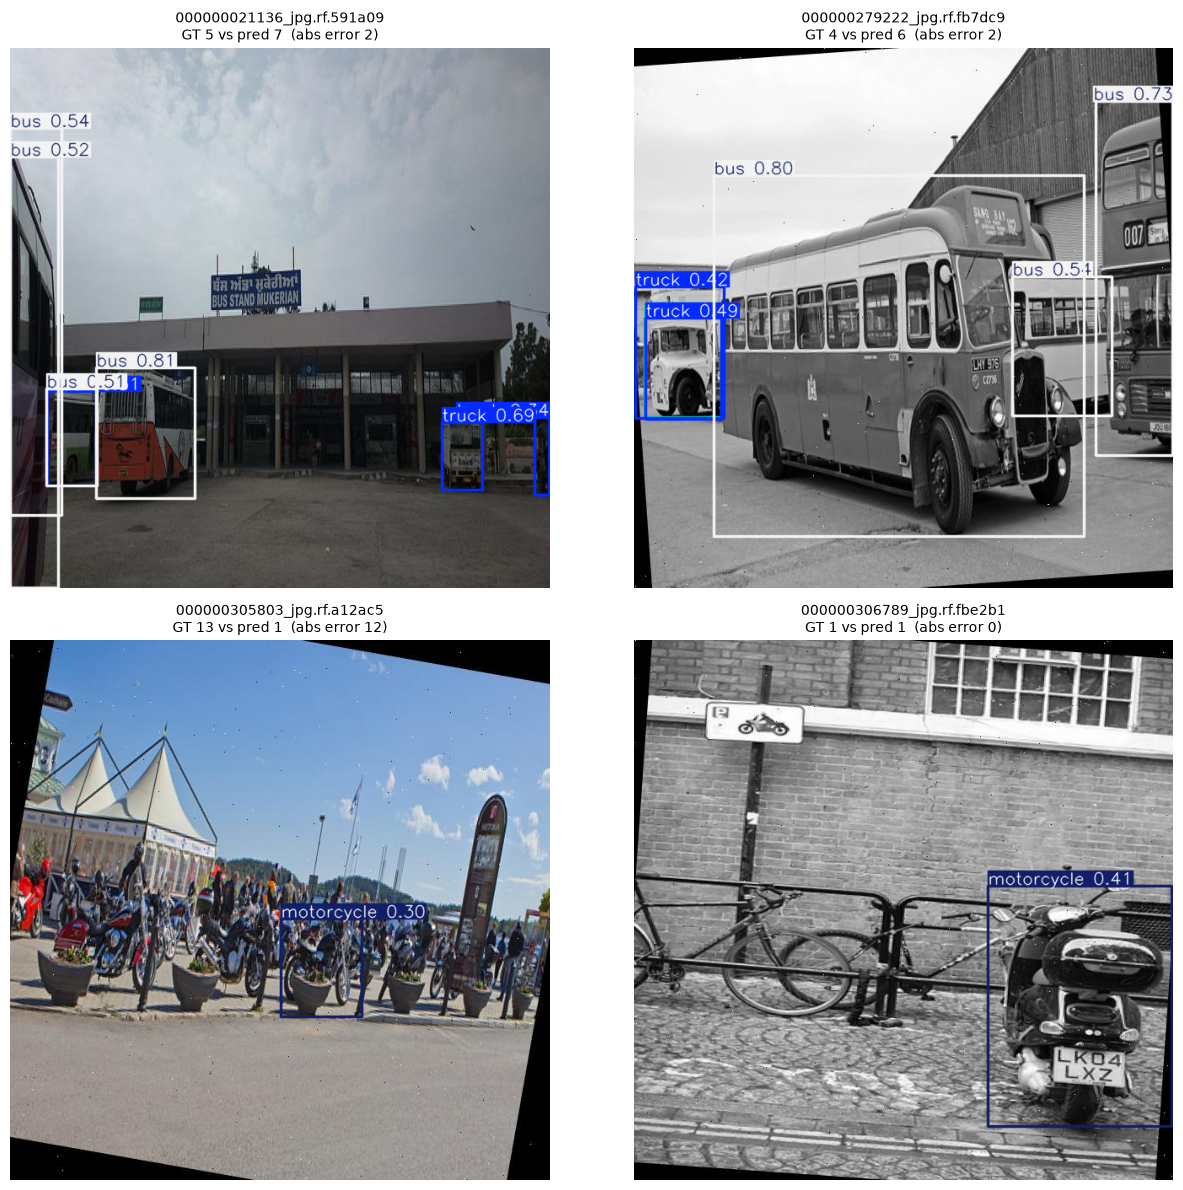

Fine-tuned mean absolute counting error: 4.0 vehicles/image on these four test images


In [10]:
if SMOKE:
    from ultralytics.utils import ASSETS
    image = ASSETS / "bus.jpg"
    result = trained.predict(str(image), conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    print("COCO8 smoke prediction classes:",
          tally_predictions(result.boxes, trained.names,
                            vehicle_classes=("car", "bus", "truck", "motorcycle")))
    plt.figure(figsize=(7, 6))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.title("COCO8 diagnostic prediction"); plt.axis("off"); plt.show()
else:
    grid = sorted((EXPORT / "test" / "images").glob("*.jpg"))[:4]
    figure, axes = plt.subplots(2, 2, figsize=(13, 12))
    errors = []
    for axis, image in zip(axes.ravel(), grid):
        result = trained.predict(str(image), conf=0.25, imgsz=IMGSZ, device=DEVICE,
                                 verbose=False)[0]
        tally = tally_predictions(result.boxes, trained.names, vehicle_classes=VEHICLE_CLASSES)
        truth = ground_truth(image)
        error = sum(abs(truth.get(k, 0) - tally["per_class"].get(k, 0))
                    for k in set(truth) | set(tally["per_class"]))
        errors.append(error)
        axis.imshow(result.plot()[:, :, ::-1])
        axis.set_title(f"{image.name[:26]}\nGT {sum(truth.values())} vs pred {tally['total']}"
                       f"  (abs error {error})", fontsize=10)
        axis.axis("off")
        print(f"{image.name}: predicted {tally['per_class']} | ground truth {truth}")
    plt.tight_layout()
    plt.show()
    print("Fine-tuned mean absolute counting error:", round(sum(errors) / len(errors), 2),
          "vehicles/image on these four test images")

**Expected output:**

```text
000000021136_jpg.rf.591a09eb79057b4a8139188b25aabd95.jpg: predicted {'bus': 4, 'truck': 3} | ground truth {'bus': 4, 'truck': 1}
000000279222_jpg.rf.fb7dc97a15f0d237311be501e45f110a.jpg: predicted {'bus': 3, 'truck': 2, 'car': 1} | ground truth {'bus': 3, 'truck': 1}
000000305803_jpg.rf.a12ac5644291b03859ee97bf32999079.jpg: predicted {'motorcycle': 1} | ground truth {'motorcycle': 13}
000000306789_jpg.rf.fbe2b1ca62b53abcb7fb9fbc765b29e0.jpg: predicted {'motorcycle': 1} | ground truth {'motorcycle': 1}
Fine-tuned mean absolute counting error: 4.0 vehicles/image on these four test images
```

**Expected output (image):**

![Detection and counting on four test images](../assets/vehicle-counting-6.png)

*Detection and counting on four test images*

## 6. Counting traffic in video: tracking plus line crossing

Counting boxes frame by frame adds the same vehicle dozens of times, so traffic counting needs two things:

1. **Tracking** (`model.track`, ByteTrack) gives every vehicle a stable `tracker_id`;
2. **Line crossing**: take the sign of the box's bottom-edge midpoint (the vehicle's ground contact point)
   relative to the counting line; a sign flip counts as one crossing, counted once per vehicle and
   direction, so turning back does not double-count (see `common/traffic_counting.py`).

First validate the counter on the synthetic clip generated by `build_traffic_demo_video.py` (six vehicles,
each crossing once), then repeat the same pipeline on a real road video with `TRAFFIC_VIDEO=<your.mp4>`.

In [11]:
VIDEO = Path(os.environ.get("TRAFFIC_VIDEO", str(OUTPUT / "traffic-demo.mp4")))
if VIDEO.exists():
    print("Using video:", VIDEO)
else:
    VIDEO.parent.mkdir(parents=True, exist_ok=True)
    truth = build_demo_video(MODULE / "data" / VEHICLE_DIRECTORY, VIDEO, fps=12, frames=108)
    print("Synthetic clip written:", VIDEO)
    print("Ground truth crossings:", truth["expected_total_crossings"],
          truth["expected_vehicles_per_class"])
ground_truth_path = VIDEO.with_suffix(".ground-truth.json")
video_truth = json.loads(ground_truth_path.read_text(encoding="utf-8")) if ground_truth_path.exists() else None
if video_truth:
    print("Counting line:", video_truth["counting_line"], "| frames:", video_truth["frames"],
          "| fps:", video_truth["fps"])

Using video: /Users/will/workspace/deep-learning-lab/english/02-object-detection/outputs/traffic-demo.mp4
Counting line: [0, 320, 640, 320] | frames: 108 | fps: 12


**Expected output:**

```text
Using video: …/deep-learning-lab/english/02-object-detection/outputs/traffic-demo.mp4
Counting line: [0, 320, 640, 320] | frames: 108 | fps: 12
```

(Inside the quoted output `…` stands for the repository's absolute path prefix on the machine that ran the notebook; yours will show your own path.)

Analysed frames: 108 of declared 108 | fps: 12.0
forward  crossings:   4  per class: {'truck': 1, 'motorcycle': 1, 'bus': 2}
backward crossings:   2  per class: {'bus': 2}
Unique counted vehicles: 6 | vehicle tracks ever seen: 10
Flow: {'duration_seconds': 9.0, 'total_crossings': 6, 'vehicles_per_minute': 40.0}
Ground-truth crossings: 6 -> detector/tracker deviation: +0


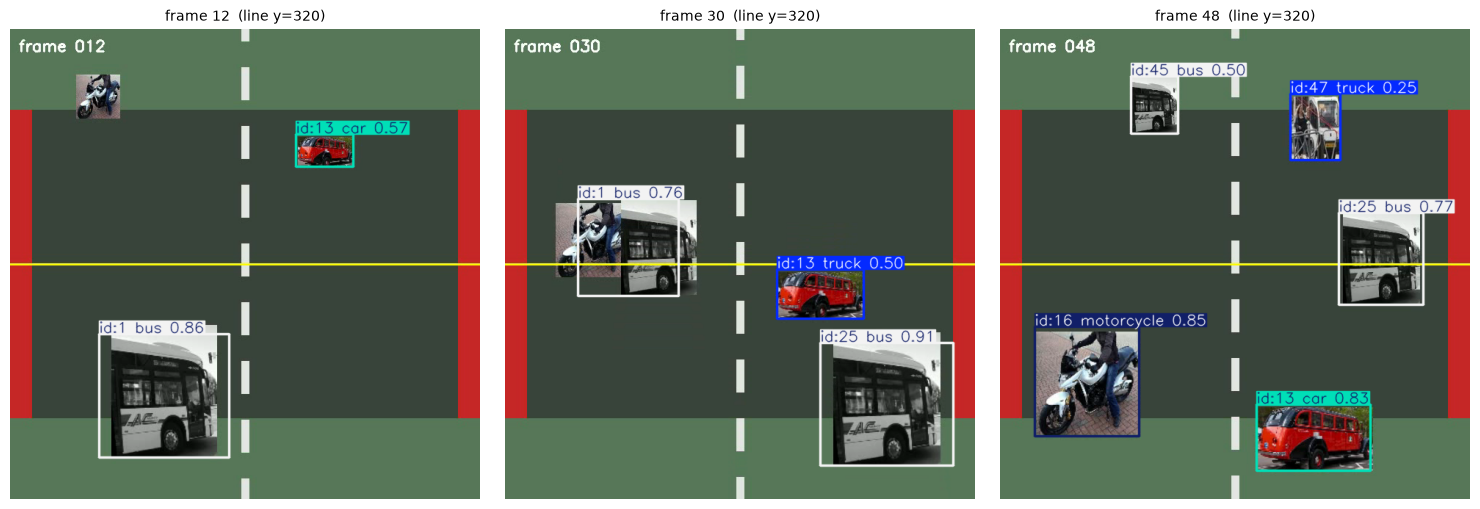

In [12]:
summary, frames = count_video(trained, VIDEO, COUNTING_LINE, conf=0.25,
                              imgsz=416 if not SMOKE else 64, device=DEVICE,
                              vehicle_classes=VEHICLE_CLASSES if not SMOKE else TALLY_CLASSES,
                              annotated_frames=(12, 30, 48))
print("Analysed frames:", summary["frames_analysed"], "of declared", summary["declared_frames"],
      "| fps:", summary["fps"])
for direction in ("forward", "backward"):
    block = summary[direction]
    print(f"{direction:8} crossings: {block['crossings']:3d}  per class: {block['per_class']}")
print("Unique counted vehicles:", summary["unique_vehicles_seen"],
      "| vehicle tracks ever seen:", summary["tracks_observed"])
print("Flow:", summary["flow"])
if video_truth:
    difference = summary["flow"]["total_crossings"] - video_truth["expected_total_crossings"]
    print("Ground-truth crossings:", video_truth["expected_total_crossings"],
          f"-> detector/tracker deviation: {difference:+d}")

figure, axes = plt.subplots(1, max(1, len(frames)), figsize=(5 * max(1, len(frames)), 5))
axes = list(numpy.atleast_1d(axes))
for axis, sample in zip(axes, frames):
    axis.imshow(sample["rgb"])
    axis.set_title(f"frame {sample['frame']}  (line y=320)", fontsize=10)
    axis.axis("off")
plt.tight_layout()
plt.show()

**Expected output:**

```text
Analysed frames: 108 of declared 108 | fps: 12.0
forward  crossings:   4  per class: {'truck': 1, 'motorcycle': 1, 'bus': 2}
backward crossings:   2  per class: {'bus': 2}
Unique counted vehicles: 6 | vehicle tracks ever seen: 10
Flow: {'duration_seconds': 9.0, 'total_crossings': 6, 'vehicles_per_minute': 40.0}
Ground-truth crossings: 6 -> detector/tracker deviation: +0
```

**Expected output (image):**

![Tracked frames and line crossings (yellow line at y=320)](../assets/vehicle-counting-7.png)

*Tracked frames and line crossings (yellow line at y=320)*

## 7. Use your own road video

The same `count_video()` works on real surveillance or dashcam video; only the counting line has to match
the resolution:

```python
TRAFFIC_VIDEO = Path("/path/to/your-road-video.mp4")
summary, frames = count_video(trained, TRAFFIC_VIDEO,
                              line=((0, 0.55 * 1080), (1920, 0.55 * 1080)), conf=0.25)
print(summary["forward"]["crossings"], summary["backward"]["crossings"], summary["flow"])
```

Tune in this order: fix `conf` first, then move the counting line, and only then touch tracker settings.
Every threshold changes the numbers, so any conclusion must state the line position, `conf`, and the
checkpoint used.

In [13]:
if SMOKE:
    print("COCO8 smoke mode does not write the traffic report.")
else:
    traffic_report = {"video": summary["video"], "video_is_synthetic": video_truth is not None,
                      "model_checkpoint": str(best), "conf": 0.25, "tracker": "bytetrack.yaml",
                      "counting_line": summary["counting_line"],
                      "fps": summary["fps"], "frames_analysed": summary["frames_analysed"],
                      "counts": {d: summary[d] for d in ("forward", "backward")},
                      "unique_vehicles_counted": summary["unique_vehicles_seen"],
                      "vehicle_tracks_observed": summary["tracks_observed"],
                      "flow": summary["flow"],
                      "ground_truth": video_truth and video_truth["expected_total_crossings"],
                      "note": "Synthetic clip: every spawned vehicle crosses once, so the "
                              "deviation measures detection and tracking quality, not traffic."}
    (OUTPUT / "vehicle-flow-report.json").write_text(json.dumps(traffic_report, indent=2),
                                                     encoding="utf-8")
    print(json.dumps({k: traffic_report[k] for k in
                      ("counts", "unique_vehicles_counted", "flow")}, indent=2, ensure_ascii=False))

{
  "counts": {
    "forward": {
      "crossings": 4,
      "per_class": {
        "truck": 1,
        "motorcycle": 1,
        "bus": 2
      },
      "last_crossing": {
        "class": "bus",
        "track_id": 61,
        "frame": 78,
        "timestamp": 6.5
      }
    },
    "backward": {
      "crossings": 2,
      "per_class": {
        "bus": 2
      },
      "last_crossing": {
        "class": "bus",
        "track_id": 25,
        "frame": 52,
        "timestamp": 4.333333333333333
      }
    }
  },
  "unique_vehicles_counted": 6,
  "flow": {
    "duration_seconds": 9.0,
    "total_crossings": 6,
    "vehicles_per_minute": 40.0
  }
}


**Expected output:**

```text
{
  "counts": {
    "forward": {
      "crossings": 4,
      "per_class": {
        "truck": 1,
        "motorcycle": 1,
        "bus": 2
      },
      "last_crossing": {
        "class": "bus",
        "track_id": 61,
        "frame": 78,
        "timestamp": 6.5
      }
    },
    "backward": {
      "crossings": 2,
      "per_class": {
        "bus": 2
      },
      "last_crossing": {
        "class": "bus",
        "track_id": 25,
        "frame": 52,
        "timestamp": 4.333333333333333
      }
    }
  },
  "unique_vehicles_counted": 6,
  "flow": {
    "duration_seconds": 9.0,
    "total_crossings": 6,
    "vehicles_per_minute": 40.0
  }
}
```

## Exercises and extensions

1. Lower `conf` from 0.25 to 0.10 and rerun the video: why does the crossing count change, and which
   classes start to jitter first?
2. Move the counting line up and down by 100 px and explain how the two directions change (where vehicles
   appear and disappear).
3. Compare detection-only counting (summing boxes per frame) with tracked counting and explain why traffic
   counting needs tracking.
4. Set `TRAFFIC_VIDEO` to a real clip and report the line position, `conf`, checkpoint, and per-class results
   together.
5. To cover more vehicle types (construction vehicles, scooters), extend the labels in the source dataset or
   collect new data, then import it through the same importer.

Sources and tools: [YOLO26 documentation](https://docs.ultralytics.com/models/yolo26/),
[ByteTrack tracking guide](https://docs.ultralytics.com/modes/track/),
[dataset v4](https://universe.roboflow.com/vehicle-counting-rtvul/vehicle-counting-tksu5/dataset/4).